# Глава 7. Регрессия

## 7.1 Создание регрессора одной переменной

In [11]:
import pickle
import numpy as np
from sklearn import linear_model
import sklearn.metrics as sm
import matplotlib.pyplot as plt

In [12]:
# Входной файл, содержащий данные
input_file = 'Lab01_data/data_singlevar_regr.txt'

# Загрузка данных
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

# Разбивка данных на обучающий и тестовый наборы
num_training = int(0.8 * len(X))
num_test = len(X) - num_training

# Тренировочные данные
X_train, y_train = X[:num_training], y[:num_training]
# Тестовые данные
X_test, y_test = X[num_training:], y[num_training:]

In [13]:
# Создание объекта линейного регрессора
regressor = linear_model.LinearRegression()

# Обучение модели с использованием обучающего набора
regressor.fit(X_train, y_train)

# Прогнозирование результата
y_test_pred = regressor.predict(X_test)

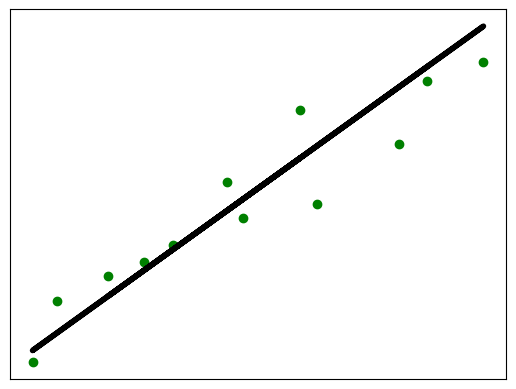

In [14]:
# Построение графика
plt.scatter(X_test, y_test, color='green')
plt.plot(X_test, y_test_pred, color='black', linewidth=4)
plt.xticks(())
plt.yticks(())
plt.show()

In [15]:
# Вычисление метрик
print("Linear regressor performance:")
print("Mean absolute error =", round(sm.mean_absolute_error(y_test, y_test_pred), 2))
print("Mean squared error =", round(sm.mean_squared_error(y_test, y_test_pred), 2))
print("Median absolute error =", round(sm.median_absolute_error(y_test, y_test_pred), 2))
print("Explain variance score =", round(sm.explained_variance_score(y_test, y_test_pred), 2))
print("R2 score =", round(sm.r2_score(y_test, y_test_pred), 2))

Linear regressor performance:
Mean absolute error = 0.59
Mean squared error = 0.49
Median absolute error = 0.51
Explain variance score = 0.86
R2 score = 0.86


In [16]:
# Файл для сохранения модели
output_model_file = 'model.pkl'

# Сохранение модели
with open(output_model_file, 'wb') as f:
    pickle.dump(regressor, f)

# Загрузка модели
with open(output_model_file, 'rb') as f:
    regressor_model = pickle.load(f)

# Получение прогноза на тестовом наборе данных
y_test_pred_new = regressor_model.predict(X_test)
print("\nNew mean absolute error =", round(sm.mean_absolute_error(y_test, y_test_pred_new), 2))


New mean absolute error = 0.59


## 7.2 Создание многомерного регрессора

In [17]:
import numpy as np
from sklearn import linear_model
import sklearn.metrics as sm
from sklearn.preprocessing import PolynomialFeatures

In [18]:
# Входной файл, содержащий данные
input_file = 'Lab01_data/data_multivar_regr.txt'

# Загрузка данных
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

# Разбивка данных на обучающий и тестовый наборы
num_training = int(0.8 * len(X))
num_test = len(X) - num_training
# Тренировочные данные
X_train, y_train = X[:num_training], y[:num_training]
# Тестовые данные
X_test, y_test = X[num_training:], y[num_training:]

In [19]:
# Создание модели линейного регрессора
linear_regressor = linear_model.LinearRegression()

# Обучение модели с использованием обучающих наборов
linear_regressor.fit(X_train, y_train)

# Прогнозирование результата
y_test_pred = linear_regressor.predict(X_test)

# Измерение метрик
print("Linear Regressor performance:")
print("Mean absolute error =", round(sm.mean_absolute_error(y_test, y_test_pred), 2))
print("Mean squared error =", round(sm.mean_squared_error(y_test, y_test_pred), 2))
print("Median absolute error =", round(sm.median_absolute_error(y_test, y_test_pred), 2))
print("Explained variance score =", round(sm.explained_variance_score(y_test, y_test_pred), 2))
print("R2 score =", round(sm.r2_score(y_test, y_test_pred), 2))

Linear Regressor performance:
Mean absolute error = 3.58
Mean squared error = 20.31
Median absolute error = 2.99
Explained variance score = 0.86
R2 score = 0.86


In [ ]:
# Полиномиальная регрессия
polynomial = PolynomialFeatures(degree=10)
X_train_transformed = polynomial.fit_transform(X_train)
datapoint = [[7.75, 6.35, 5.56]]
poly_datapoint = polynomial.fit_transform(datapoint)

poly_linear_model = linear_model.LinearRegression()
poly_linear_model.fit(X_train_transformed, y_train)
print("\nLinear regression:\n", linear_regressor.predict(datapoint))
print("\nPolynomial regression:\n", poly_linear_model.predict(poly_datapoint))


Linear regression:
 [36.05286276]

Polynomial regression:
 [31.63944054]


: 